In [ ]:
class AnalizadorImagen:
    def __init__(self, ruta, escala_nm_px=None):
        self.ruta = ruta
        self.escala = escala_nm_px
        self.imagen = None

    def cargar(self):
        self.imagen = ski.io.imread(self.ruta)   # código común para leer la imagen

    def analizar(self):
        raise NotImplementedError("Cada técnica implementa su análisis")

c:\Disco D\Study\Phd Bariloche\Asignaturas\Materia_python\Proyecto\Analizador-de-im-genes-de-microscop-a\dominio_moke.py:114: UserWarning: El contraste es bajo comparado con el ruido: revisá el resultado.
  warnings.warn("El contraste es bajo comparado con el ruido: revisá el resultado.")


0.png (1920, 2560)


c:\Disco D\Study\Phd Bariloche\Asignaturas\Materia_python\Proyecto\Analizador-de-im-genes-de-microscop-a\dominio_moke.py:114: UserWarning: El contraste es bajo comparado con el ruido: revisá el resultado.
  warnings.warn("El contraste es bajo comparado con el ruido: revisá el resultado.")


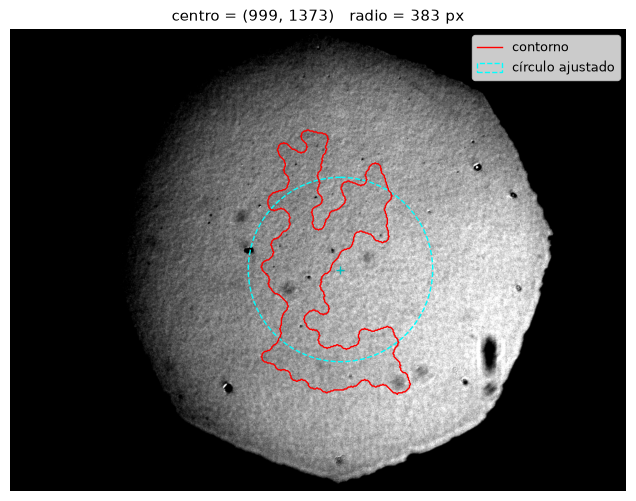

(999.0512157108609, 1372.8603171300092) 191.6092628533394 77684.0
6.png (1920, 2560)


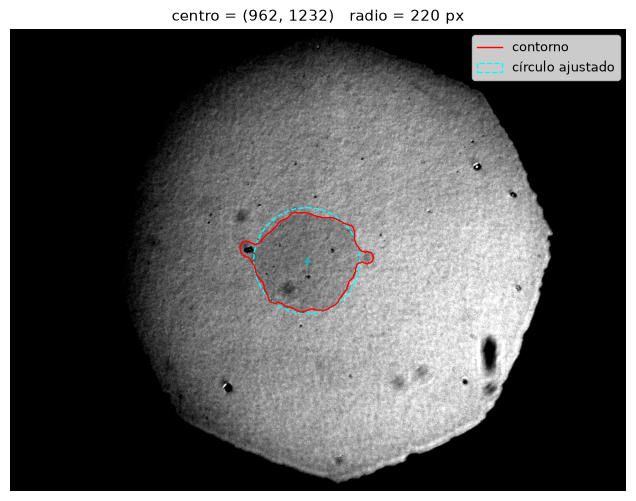

(961.874861609254, 1232.4141971842407) 109.93923509902581 36044.0
7.png (1920, 2560)


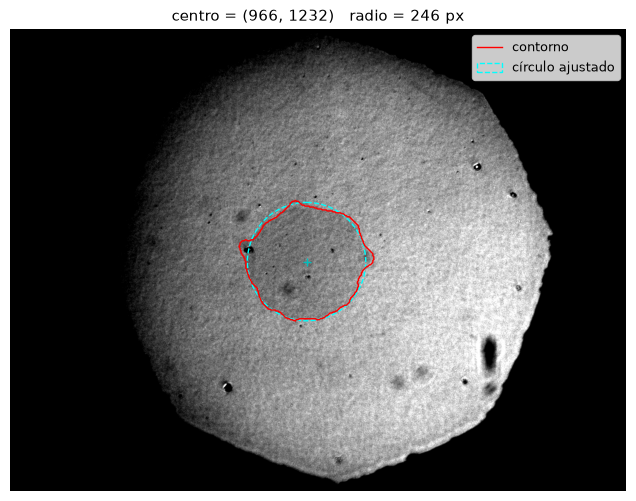

(966.2656240202695, 1231.9862111514126) 122.94354998857763 46928.0
8.png (1920, 2560)


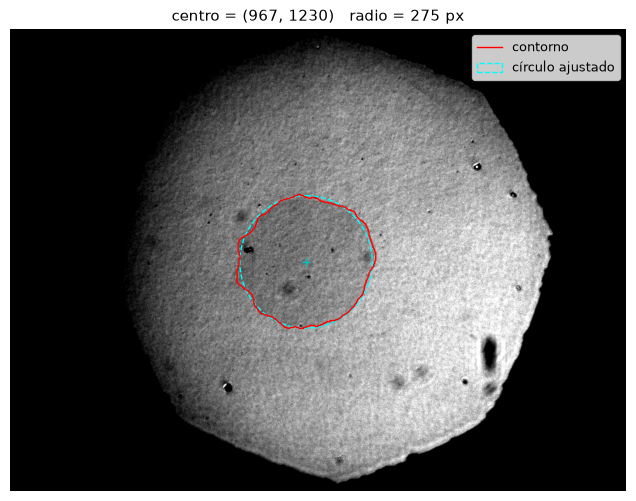

(967.2957186825308, 1229.8261004947967) 137.65218757752592 59416.0
9.png (1920, 2560)


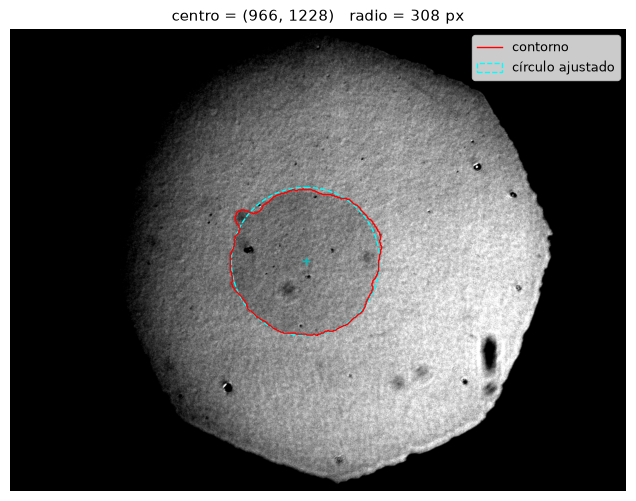

(965.6477244219975, 1227.6811591619244) 154.13923589873994 74288.0
10.png (1920, 2560)


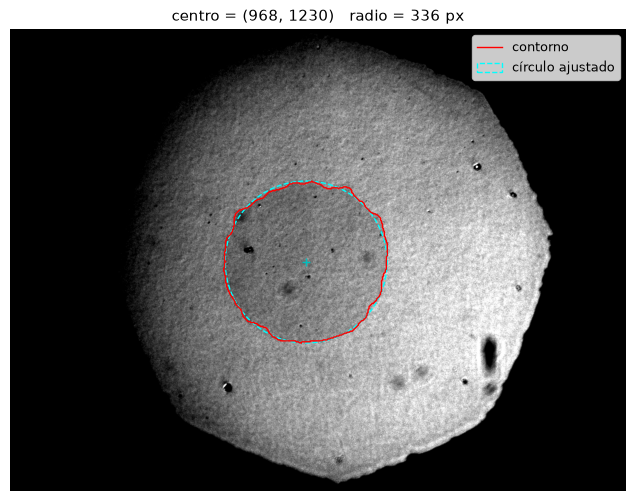

(967.8672835617266, 1230.2117245595937) 168.21266126772545 88760.0
11.png (1920, 2560)


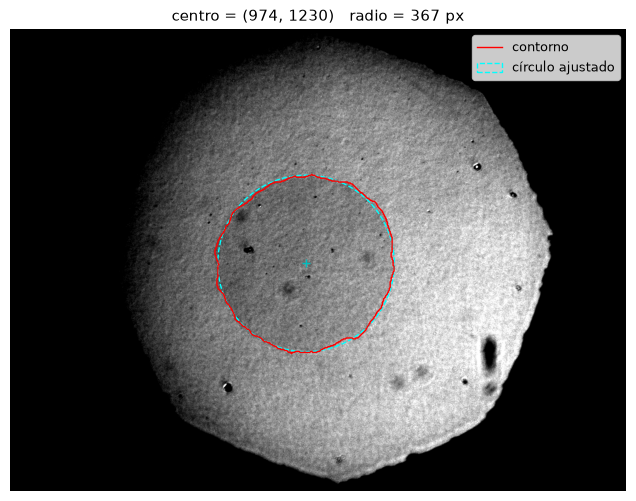

(973.6653357842897, 1229.8505333292103) 183.37948820533038 105524.0
12.png (1920, 2560)


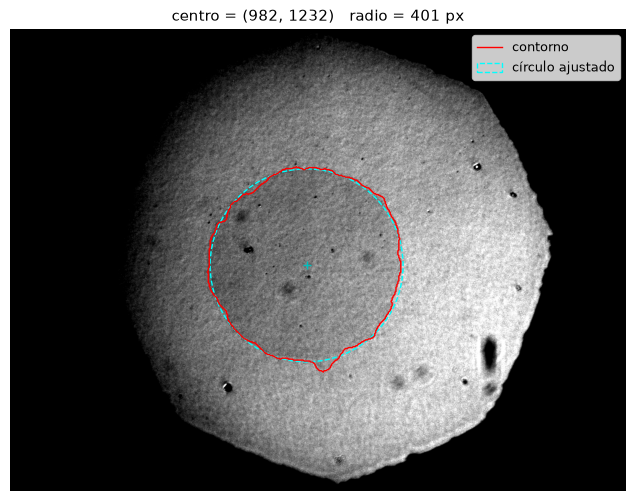

(981.7750878706589, 1232.1290120670483) 200.50464102895958 125920.0
13.png (1920, 2560)


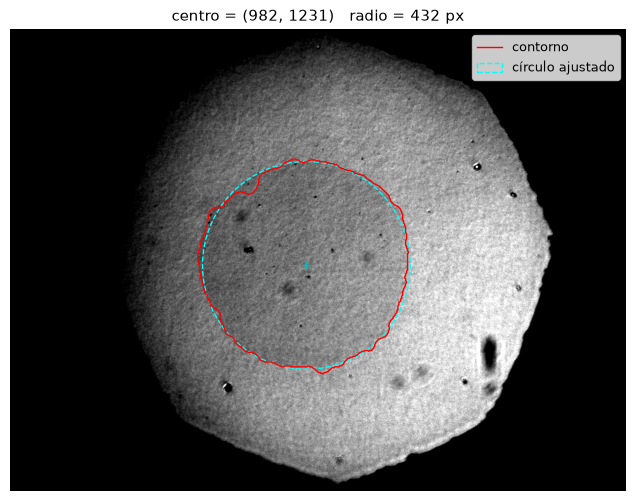

(981.7595259712712, 1231.1361806649757) 215.82556754075227 146316.0
14.png (1920, 2560)


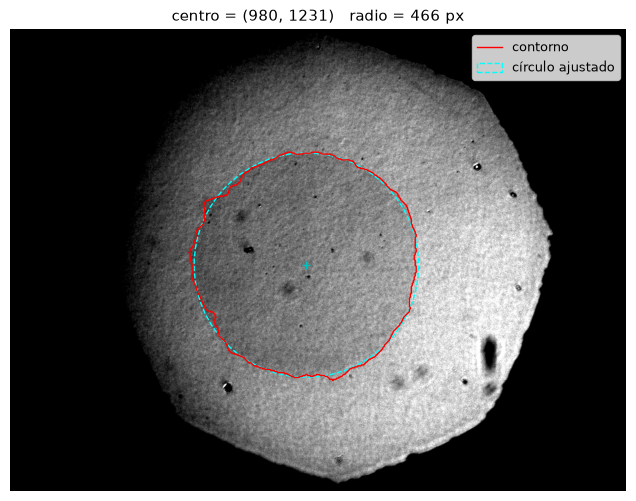

(980.4115542473064, 1231.120823091724) 233.13582285016426 170512.0
15.png (1920, 2560)


c:\Disco D\Study\Phd Bariloche\Asignaturas\Materia_python\Proyecto\Analizador-de-im-genes-de-microscop-a\dominio_moke.py:114: UserWarning: El contraste es bajo comparado con el ruido: revisá el resultado.
  warnings.warn("El contraste es bajo comparado con el ruido: revisá el resultado.")


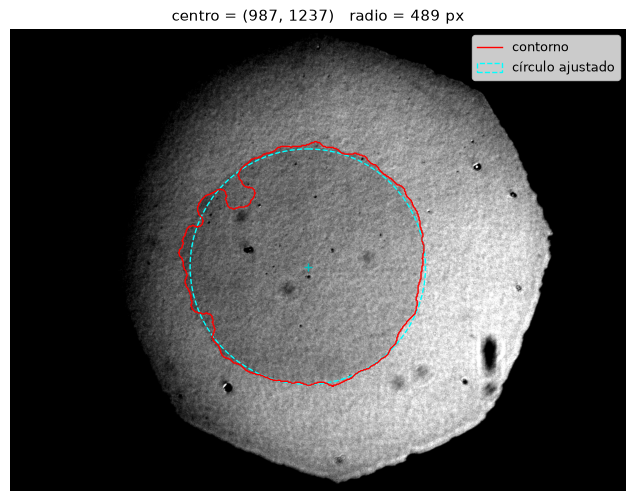

(987.1688885834623, 1237.159079539364) 244.60778346197043 184744.0


In [19]:
from pathlib import Path
import csv
import matplotlib.pyplot as plt
import skimage as ski
from dominio_moke import detectar_dominio, mostrar_dominio

scale = 0.5  # nm/px

carpeta = Path("evolucion_dominio")
salida = Path("resultados")
salida.mkdir(exist_ok=True)

archivos = sorted(carpeta.glob("*.png"), key=lambda f: int(f.stem))

# La última imagen (dominio más grande) da un punto de adentro para las demás
semilla = detectar_dominio(ski.io.imread(archivos[-1]))["centro"]

with open(salida / "medidas.csv", "w", newline="") as tabla:
    w = csv.writer(tabla)
    w.writerow(["archivo", "fila_centro_px", "col_centro_px", "radio_px",
                "radio_nm", "area_nm2", "contraste", "dudoso"])

    for f in archivos:
        img = ski.io.imread(f)
        print(f.name, img.shape)

        try:
            res = detectar_dominio(img, semilla=semilla)
        except ValueError as error:
            print("  no se detectó dominio:", error)
            continue

        # Figura: se guarda y se muestra
        ax = mostrar_dominio(img, res)
        ax.figure.savefig(salida / f"dominio_{f.stem}.png", dpi=150, bbox_inches="tight")
        plt.show()

        # Medidas: se imprimen y se agregan a la tabla
        radio = scale * res["radio"]
        area = scale**2 * res["area"]
        dudoso = abs(res["contraste"]) < 3 * res["ruido"]
        print(res["centro"], radio, area)
        w.writerow([f.name, round(res["centro"][0], 1), round(res["centro"][1], 1),
                    round(res["radio"], 1), round(radio, 1), round(area, 1),
                    round(res["contraste"], 3), dudoso])

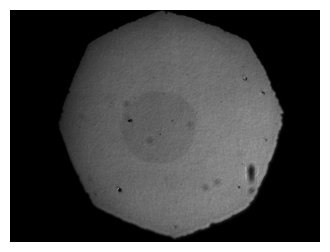

In [3]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(img, cmap='gray')
ax.axis('off')
plt.show()